In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
warnings.filterwarnings('ignore')

ROOT = Path.cwd().resolve()
while not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.features.feature_groups import FEATURE_GROUPS, GROUP_COLORS, COLUMN_TO_GROUP
from src.data import eda_checks as E

FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / 'reports' / 'tables'; TAB.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200, 'display.max_rows', 120, 'display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
GC = {g: '#' + c for g, c in GROUP_COLORS.items()}

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', bbox_inches='tight'); plt.show()

from src.data.loading import load_raw, NA_IS_CATEGORY, TRAIN_PATH, TEST_PATH
# 'NA' stays a string only where it is a documented category (feature absent); elsewhere it is NaN.
raw = load_raw(TRAIN_PATH)
test = load_raw(TEST_PATH)
print(raw.shape, test.shape)

(1460, 81) (1459, 80)


In [2]:
import hashlib
files = ['train.csv', 'test.csv', 'data_description.txt', 'sample_submission.csv']
print(pd.DataFrame([(f, (ROOT/'Dataset'/f).stat().st_size, hashlib.md5((ROOT/'Dataset'/f).read_bytes()).hexdigest()) for f in files],
                   columns=['file', 'bytes', 'md5']).to_string(index=False))
print('Proposal check -> train', raw.shape, '(expected 1460 x 81) | test', test.shape, '(expected 1459 x 80)')

                 file  bytes                              md5
            train.csv 462137 dbfd1a4af4117b7ec1d130572d9c6d7b
             test.csv 452865 9e655ff088e2f1771853855c0ce2312b
 data_description.txt  13893 69aa4d1ae23875bbb65e29edf296e822
sample_submission.csv  33399 37d7241b531096b9273547d2c2a3f2ee
Proposal check -> train (1460, 81) (expected 1460 x 81) | test (1459, 80) (expected 1459 x 80)


In [3]:
print('Duplicate rows (excl. Id):', raw.drop(columns='Id').duplicated().sum(), '| Id unique:', raw.Id.is_unique)
print('Columns only in train:', set(raw.columns) - set(test.columns))
nominal_codes = ['MSSubClass']                    # numeric in file, nominal in meaning
num_cols = [c for c in raw.select_dtypes('number').columns if c not in ['Id', 'SalePrice'] + nominal_codes]
cat_cols = [c for c in raw.columns if c not in num_cols + ['Id', 'SalePrice']]
print(f'numeric: {len(num_cols)}  categorical (incl. MSSubClass): {len(cat_cols)}')
summary = pd.DataFrame({'group': pd.Series(COLUMN_TO_GROUP), 'dtype': raw.dtypes.astype(str), 'n_unique': raw.nunique()})
summary.groupby('group').agg(columns=('dtype', 'size'), numeric=('dtype', lambda s: (s != 'object').sum()))

Duplicate rows (excl. Id): 0 | Id unique: True
Columns only in train: {'SalePrice'}
numeric: 35  categorical (incl. MSSubClass): 44


,columns,numeric
group,,
Age,3,3
Amenities,10,8
Dwelling type and structure,14,2
Identifier / Target,2,2
Location and lot,14,2
Quality and condition,17,2
Sale context,4,2
Size,17,17


count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
skew raw = 1.88, skew log1p = 0.12; kurtosis raw = 6.54, log1p = 0.81


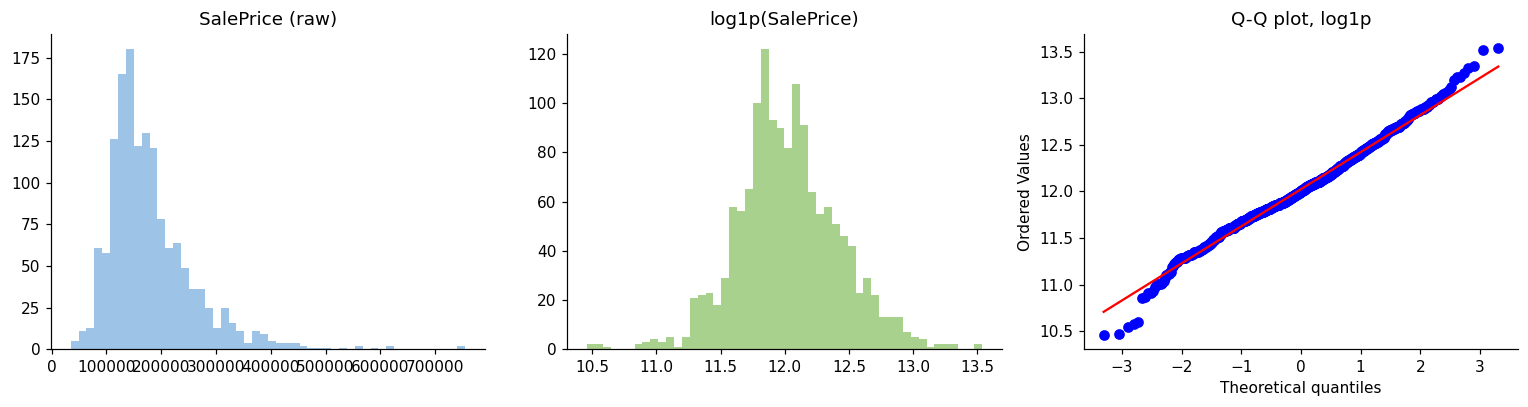

In [4]:
y = raw.SalePrice
print(y.describe().round(0).to_string())
print(f'skew raw = {y.skew():.2f}, skew log1p = {np.log1p(y).skew():.2f}; kurtosis raw = {y.kurt():.2f}, log1p = {np.log1p(y).kurt():.2f}')
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(y, bins=50, color='#9DC3E6'); ax[0].set_title('SalePrice (raw)')
ax[1].hist(np.log1p(y), bins=50, color='#A9D18E'); ax[1].set_title('log1p(SalePrice)')
from scipy import stats
stats.probplot(np.log1p(y), plot=ax[2]); ax[2].set_title('Q-Q plot, log1p')
savefig('01_target_distribution')

In [5]:
absent = pd.Series({c: int((raw[c] == 'NA').sum()) for c in NA_IS_CATEGORY})   # 'NA' = feature absent
genuine = raw.isna().sum()
miss = pd.DataFrame({'absent_feature(NA category)': absent, 'genuinely_missing(NaN)': genuine}).fillna(0).astype(int)
miss['total'] = miss.sum(axis=1)
miss = miss[miss.total > 0].sort_values('total', ascending=False)
miss['pct'] = (miss.total / len(raw) * 100).round(1)
miss['test_genuinely_missing'] = test.isna().sum().reindex(miss.index).fillna(0).astype(int)
miss

,absent_feature(NA category),genuinely_missing(NaN),total,pct,test_genuinely_missing
PoolQC,1453,0,1453,99.5,0
MiscFeature,1406,0,1406,96.3,0
Alley,1369,0,1369,93.8,0
Fence,1179,0,1179,80.8,0
FireplaceQu,690,0,690,47.3,0
LotFrontage,0,259,259,17.7,227
GarageFinish,81,0,81,5.5,0
GarageQual,81,0,81,5.5,0
GarageType,81,0,81,5.5,0
GarageYrBlt,0,81,81,5.5,78


In [6]:
# Does 'NA' coincide with a zero-sized numeric twin? (=> structural absence, not missing data)
checks = {
 'GarageType NA  vs GarageArea == 0':    (raw.GarageType.eq('NA'),   raw.GarageArea.eq(0)),
 'BsmtQual NA    vs TotalBsmtSF == 0':   (raw.BsmtQual.eq('NA'),     raw.TotalBsmtSF.eq(0)),
 'FireplaceQu NA vs Fireplaces == 0':    (raw.FireplaceQu.eq('NA'),  raw.Fireplaces.eq(0)),
 'PoolQC NA      vs PoolArea == 0':      (raw.PoolQC.eq('NA'),       raw.PoolArea.eq(0)),
}
for k, (a, b) in checks.items():
    print(f'{k:40s} NA rows={a.sum():5d}  identical to zero-twin: {bool((a == b).all())}')
print('GarageYrBlt NaN vs no garage        :', raw.GarageYrBlt.isna().sum(), bool((raw.GarageYrBlt.isna() == raw.GarageType.eq('NA')).all()))
print()
print('Basement odd rows  (BsmtQual present but BsmtExposure / BsmtFinType2 = NA):',
      raw[raw.BsmtExposure.eq('NA') & ~raw.BsmtQual.eq('NA')].Id.tolist(), raw[raw.BsmtFinType2.eq('NA') & ~raw.BsmtQual.eq('NA')].Id.tolist())
print("MasVnrType 'None' (real category):", raw.MasVnrType.eq('None').sum(), '| genuinely missing:', raw.MasVnrType.isna().sum(),
      '| MasVnrArea missing on the same rows:', bool((raw.MasVnrType.isna() == raw.MasVnrArea.isna()).all()))
print('LotFrontage missing:', raw.LotFrontage.isna().sum(), '| Electrical missing (Id):', raw.loc[raw.Electrical.isna(), 'Id'].tolist())

GarageType NA  vs GarageArea == 0        NA rows=   81  identical to zero-twin: True
BsmtQual NA    vs TotalBsmtSF == 0       NA rows=   37  identical to zero-twin: True
FireplaceQu NA vs Fireplaces == 0        NA rows=  690  identical to zero-twin: True
PoolQC NA      vs PoolArea == 0          NA rows= 1453  identical to zero-twin: True
GarageYrBlt NaN vs no garage        : 81 True

Basement odd rows  (BsmtQual present but BsmtExposure / BsmtFinType2 = NA): [949] [333]
MasVnrType 'None' (real category): 864 | genuinely missing: 8 | MasVnrArea missing on the same rows: True
LotFrontage missing: 259 | Electrical missing (Id): [1380]


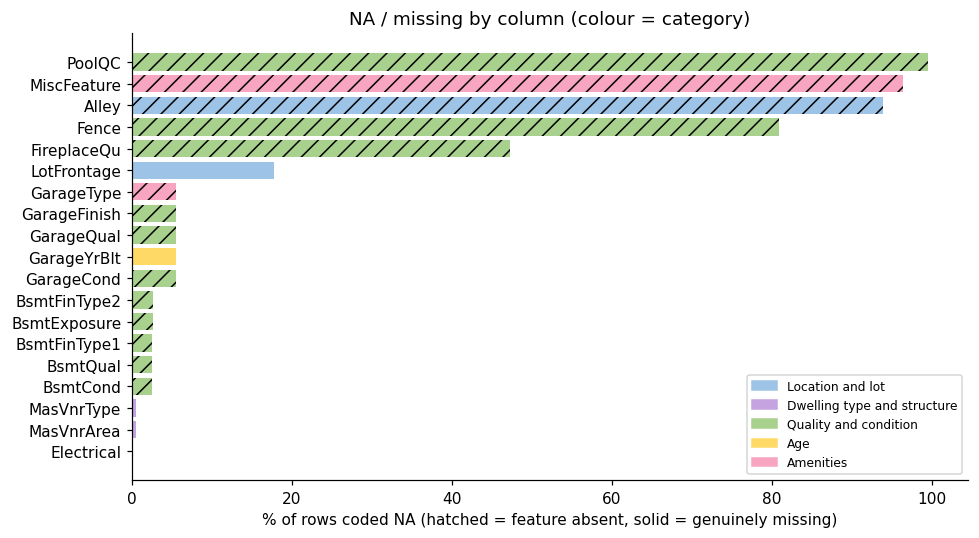

Neighborhood,BrDale,MeadowV,Blueste,NPkVill,Blmngtn,BrkSide,SWISU,IDOTRR,OldTown,StoneBr,Gilbert,Edwards,SawyerW,Veenker,CollgCr,Sawyer,Mitchel,NAmes,Somerst,Crawfor,NWAmes,ClearCr,Timber,NridgHt,NoRidge
count,16.0,15.0,2.0,7.0,14.0,51.0,23.0,34.0,109.0,20.0,49.0,92.0,50.0,7.0,126.0,48.0,36.0,186.0,78.0,41.0,45.0,13.0,30.0,76.0,33.0
median,21.0,21.0,24.0,24.0,43.0,52.0,60.0,60.0,60.0,61.5,65.0,65.5,66.5,68.0,70.0,71.0,73.0,73.0,73.5,74.0,80.0,80.0,85.0,88.5,91.0
n_missing,0.0,2.0,0.0,2.0,3.0,7.0,2.0,3.0,4.0,5.0,30.0,8.0,9.0,4.0,24.0,26.0,13.0,39.0,8.0,10.0,28.0,15.0,8.0,1.0,8.0


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
m = miss.sort_values('pct')
ax.barh(m.index, m.pct, color=[GC[COLUMN_TO_GROUP[c]] for c in m.index], hatch=['' if c not in NA_IS_CATEGORY else '//' for c in m.index])
ax.set_xlabel('% of rows coded NA (hatched = feature absent, solid = genuinely missing)'); ax.set_title('NA / missing by column (colour = category)')
ax.legend(handles=[Patch(color=GC[g], label=g) for g in GC if g in set(COLUMN_TO_GROUP[c] for c in m.index)], loc='lower right', fontsize=8)
savefig('02_missingness')
# LotFrontage is the one large genuine gap: how does it vary by neighbourhood?
lf = raw.groupby('Neighborhood').LotFrontage.agg(['count', 'median']).round(1)
lf['n_missing'] = raw[raw.LotFrontage.isna()].groupby('Neighborhood').size().reindex(lf.index).fillna(0).astype(int)
lf.sort_values('median').T

In [8]:
# Is LotFrontage missingness random? Compare the share missing across lot configuration and shape.
for c in ['LotConfig', 'LotShape']:
    t = raw.groupby(c).LotFrontage.agg(n='size', pct_missing=lambda s: round(s.isna().mean() * 100, 1))
    display(t.T)

LotConfig,Corner,CulDSac,FR2,FR3,Inside
n,263.0,94.0,47.0,4.0,1052.0
pct_missing,23.6,52.1,29.8,0.0,12.7


LotShape,IR1,IR2,IR3,Reg
n,484.0,41.0,10.0,925.0
pct_missing,34.5,36.6,30.0,8.0


In [9]:
numdf = raw[num_cols]
desc = numdf.describe().T[['count', 'mean', '50%', 'max']]
desc['skew'] = numdf.skew(); desc['zero_%'] = (numdf == 0).mean() * 100
desc['corr_log_price'] = numdf.corrwith(np.log1p(y))
desc['group'] = desc.index.map(COLUMN_TO_GROUP)
desc.round(2).sort_values('corr_log_price', key=abs, ascending=False)

,count,mean,50%,max,skew,zero_%,corr_log_price,group
OverallQual,1460.0,6.10,6.0,10.0,0.22,0.00,0.82,Quality and condition
GrLivArea,1460.0,1515.46,1464.0,5642.0,1.37,0.00,0.70,Size
GarageCars,1460.0,1.77,2.0,4.0,-0.34,5.55,0.68,Size
GarageArea,1460.0,472.98,480.0,1418.0,0.18,5.55,0.65,Size
TotalBsmtSF,1460.0,1057.43,991.5,6110.0,1.52,2.53,0.61,Size
1stFlrSF,1460.0,1162.63,1087.0,4692.0,1.38,0.00,0.60,Size
FullBath,1460.0,1.57,2.0,3.0,0.04,0.62,0.59,Size
YearBuilt,1460.0,1971.27,1973.0,2010.0,-0.61,0.00,0.59,Age
YearRemodAdd,1460.0,1984.87,1994.0,2010.0,-0.50,0.00,0.57,Age
GarageYrBlt,1379.0,1978.51,1980.0,2010.0,-0.65,0.00,0.54,Age


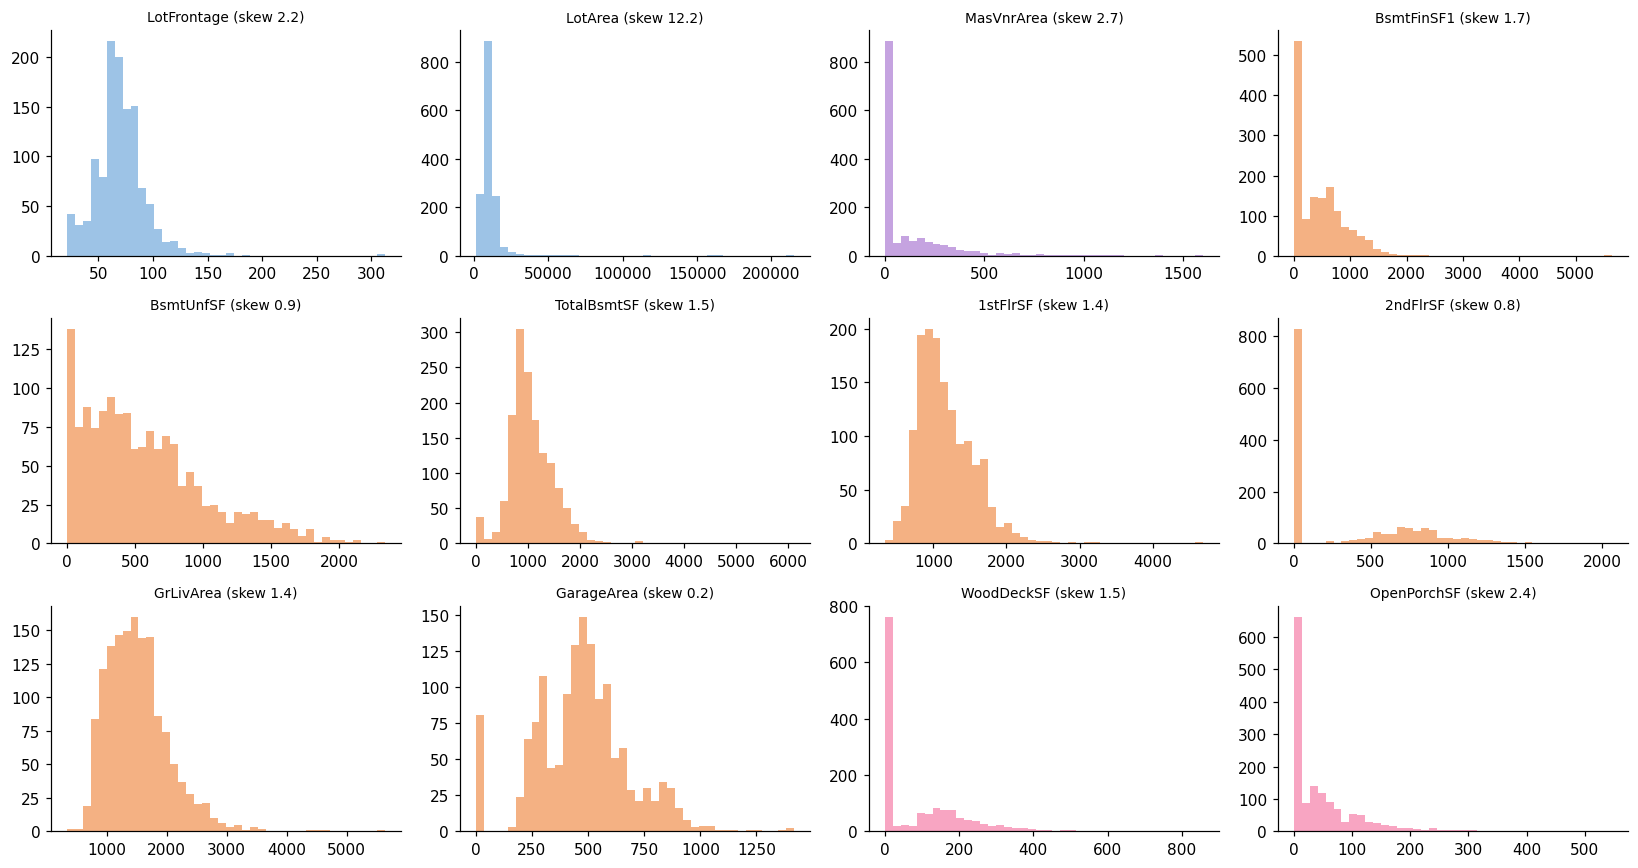

In [10]:
size_like = [c for c in num_cols if c in ('LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtUnfSF','TotalBsmtSF','1stFlrSF','2ndFlrSF','GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF')]
fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for a, c in zip(axes.ravel(), size_like):
    a.hist(numdf[c].dropna(), bins=40, color=GC[COLUMN_TO_GROUP[c]]); a.set_title(f'{c} (skew {numdf[c].skew():.1f})', fontsize=9)
savefig('03_numeric_distributions')

,pearson,spearman,gap
OverallQual,0.791,0.810,0.019
GrLivArea,0.709,0.731,0.023
GarageCars,0.640,0.691,0.050
YearBuilt,0.523,0.653,0.130
GarageArea,0.623,0.649,0.026
FullBath,0.561,0.636,0.075
TotalBsmtSF,0.614,0.603,-0.011
GarageYrBlt,0.486,0.594,0.107
1stFlrSF,0.606,0.575,-0.030
YearRemodAdd,0.507,0.571,0.064


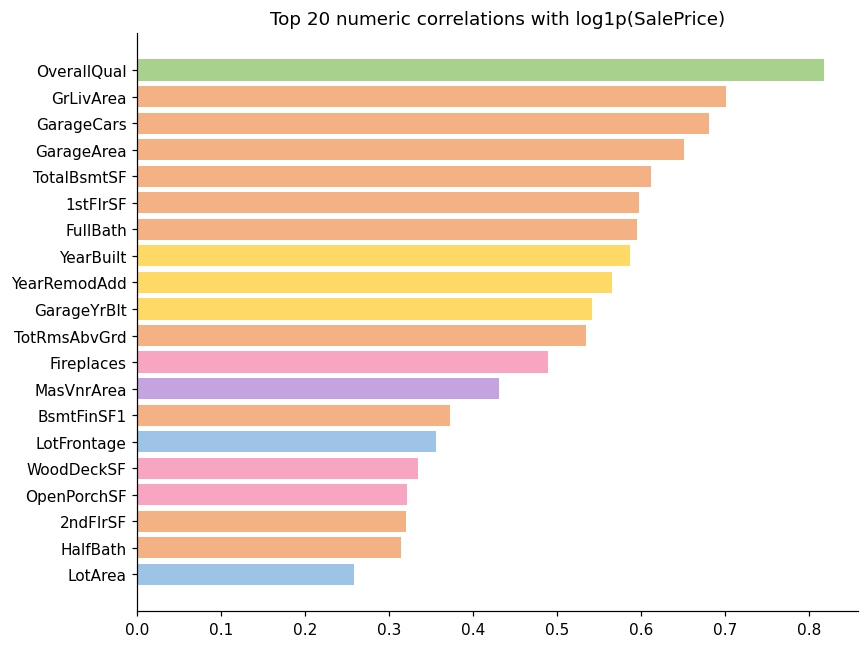

In [11]:
logp = np.log1p(y)
sp = numdf.corrwith(y, method='spearman'); pe = numdf.corrwith(y)
cmp_ = pd.DataFrame({'pearson': pe, 'spearman': sp, 'gap': sp.abs() - pe.abs()}).dropna()
display(cmp_.reindex(cmp_.spearman.abs().sort_values(ascending=False).index).head(12).round(3))
corr = numdf.corrwith(logp).dropna().sort_values()
top = corr.reindex(corr.abs().sort_values(ascending=False).index[:20]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[GC[COLUMN_TO_GROUP[c]] for c in top.index])
ax.set_title('Top 20 numeric correlations with log1p(SalePrice)')
savefig('04_top_correlations')

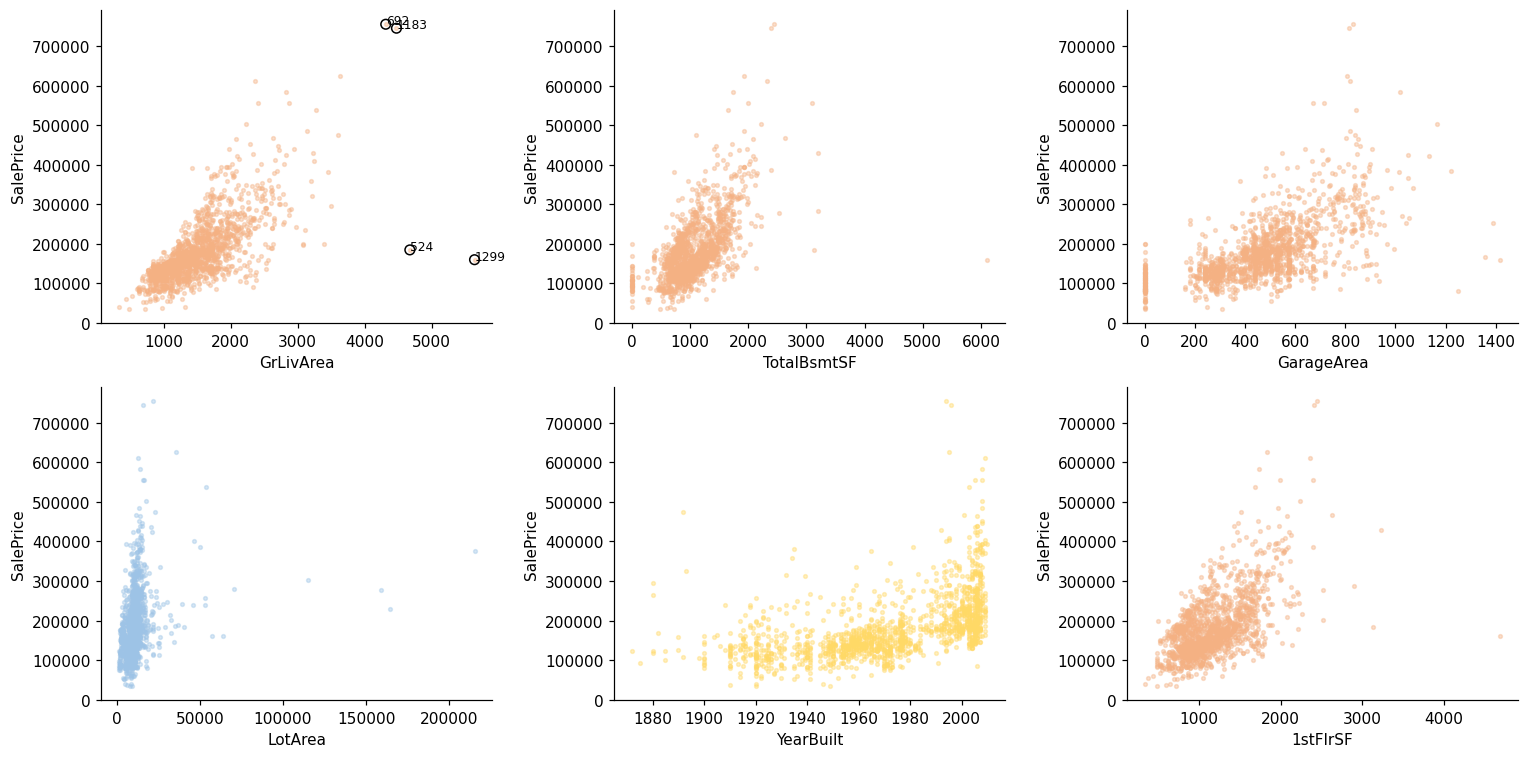

In [12]:
key = ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'LotArea', 'YearBuilt', '1stFlrSF']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(axes.ravel(), key):
    a.scatter(numdf[c], y, s=6, alpha=.4, color=GC[COLUMN_TO_GROUP[c]]); a.set_xlabel(c); a.set_ylabel('SalePrice')
    if c == 'GrLivArea':
        o = raw[(numdf[c] > 4000)]; a.scatter(o.GrLivArea, o.SalePrice, s=40, facecolors='none', edgecolors='k')
        for _, r in o.iterrows(): a.annotate(int(r.Id), (r.GrLivArea, r.SalePrice), fontsize=8)
savefig('05_scatter_key_features')

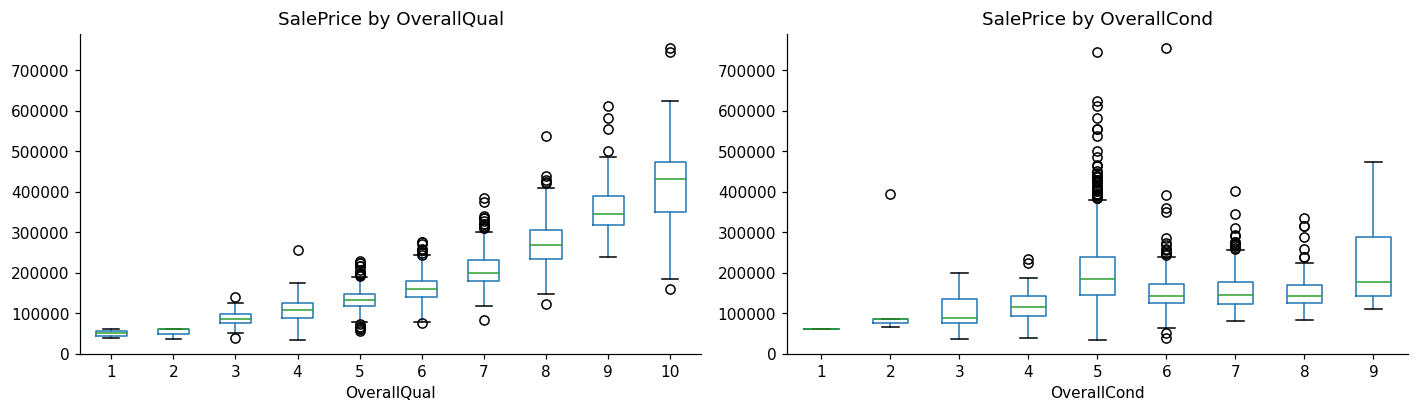

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
raw.boxplot(column='SalePrice', by='OverallQual', ax=ax[0], grid=False); ax[0].set_title('SalePrice by OverallQual'); ax[0].set_xlabel('OverallQual')
raw.boxplot(column='SalePrice', by='OverallCond', ax=ax[1], grid=False); ax[1].set_title('SalePrice by OverallCond'); ax[1].set_xlabel('OverallCond')
plt.suptitle(''); savefig('06_price_by_quality_condition')

In [14]:
card = pd.DataFrame({'n_levels': raw[cat_cols].nunique(),
                     'top_level_%': raw[cat_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1),
                     'rarest_level_n': raw[cat_cols].apply(lambda s: s.value_counts().iloc[-1]),
                     'group': pd.Series(COLUMN_TO_GROUP)}).loc[cat_cols]
card.sort_values('top_level_%', ascending=False)

,n_levels,top_level_%,rarest_level_n,group
Utilities,2.0,99.9,1.0,Location and lot
Street,2.0,99.6,6.0,Location and lot
PoolQC,4.0,99.5,2.0,Quality and condition
Condition2,8.0,99.0,1.0,Location and lot
RoofMatl,8.0,98.2,1.0,Dwelling type and structure
Heating,6.0,97.8,1.0,Dwelling type and structure
MiscFeature,5.0,96.3,1.0,Amenities
LandSlope,3.0,94.7,13.0,Location and lot
Alley,3.0,93.8,41.0,Location and lot
CentralAir,2.0,93.5,95.0,Dwelling type and structure


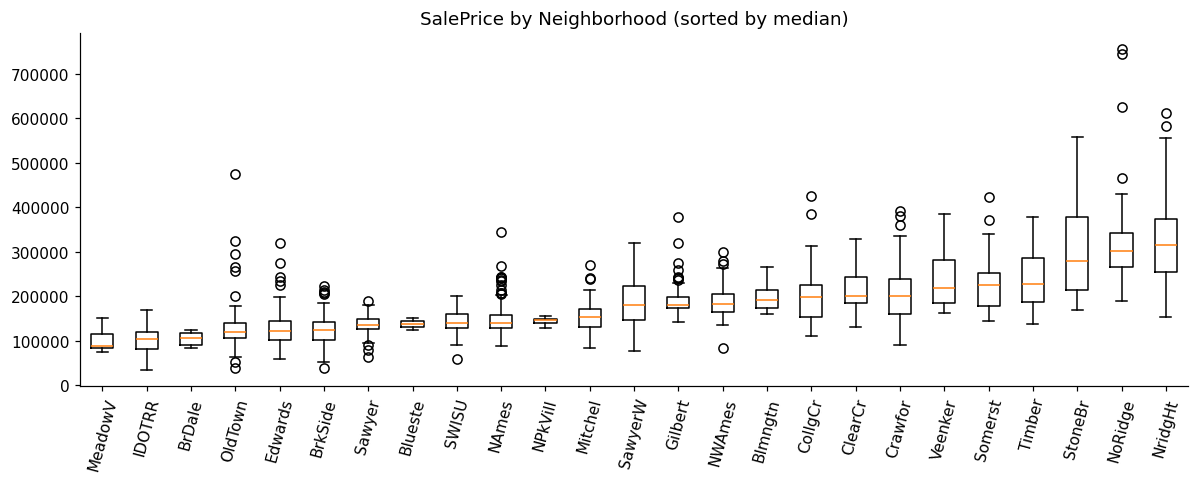

Neighborhood,MeadowV,IDOTRR,BrDale,OldTown,Edwards,BrkSide,Sawyer,Blueste,SWISU,NAmes,NPkVill,Mitchel,SawyerW,Gilbert,NWAmes,Blmngtn,CollgCr,ClearCr,Crawfor,Veenker,Somerst,Timber,StoneBr,NoRidge,NridgHt
count,17.0,37.0,16.0,113.0,100.0,58.0,74.0,2.0,25.0,225.0,9.0,49.0,59.0,79.0,73.0,17.0,150.0,28.0,51.0,11.0,86.0,38.0,25.0,41.0,77.0
median,88000.0,103000.0,106000.0,119000.0,121750.0,124300.0,135000.0,137500.0,139500.0,140000.0,146000.0,153500.0,179900.0,181000.0,182900.0,191000.0,197200.0,200250.0,200624.0,218000.0,225500.0,228475.0,278000.0,301500.0,315000.0
std,23491.0,33377.0,14330.0,52651.0,43209.0,40349.0,22345.0,19092.0,32623.0,33075.0,9377.0,36487.0,55652.0,35987.0,37172.0,30393.0,51404.0,50232.0,68866.0,72369.0,56178.0,64846.0,112970.0,121413.0,96393.0
cv,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
nb_stats = raw.groupby('Neighborhood').SalePrice.agg(['count', 'median', 'std']).sort_values('median')
order = nb_stats.index
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([raw.SalePrice[raw.Neighborhood == n] for n in order], tick_labels=order, showfliers=True)
ax.tick_params(axis='x', rotation=75); ax.set_title('SalePrice by Neighborhood (sorted by median)')
savefig('07_price_by_neighborhood')
nb_stats.assign(cv=(nb_stats['std'] / nb_stats['median']).round(2)).T.round(0)

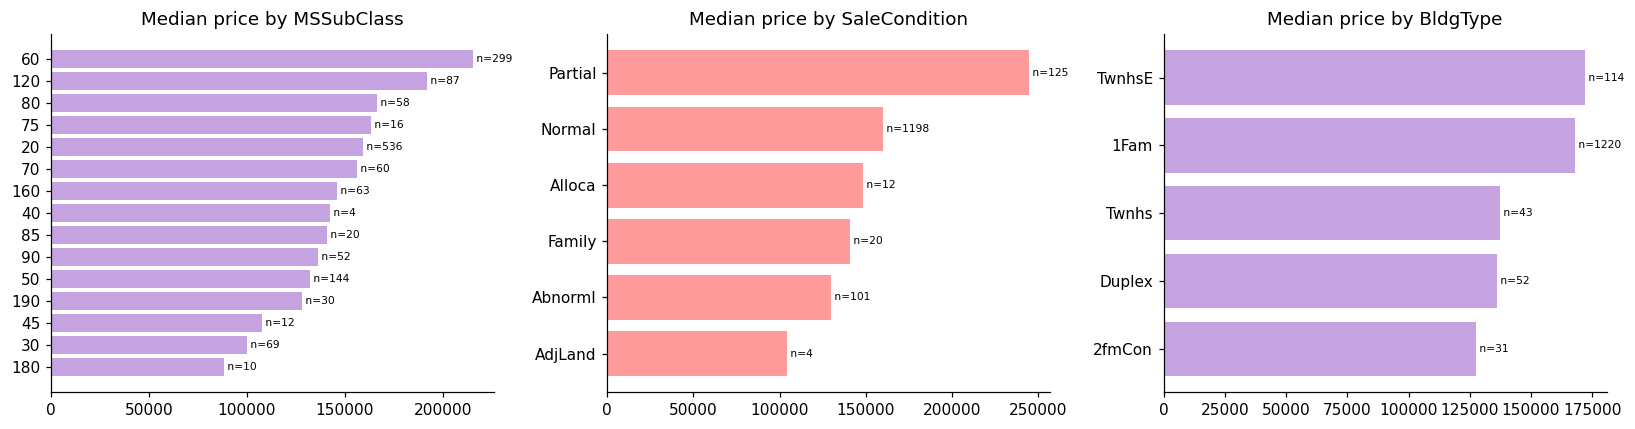

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(axes, ['MSSubClass', 'SaleCondition', 'BldgType']):
    s = raw.groupby(c).SalePrice.agg(['count', 'median']).sort_values('median')
    a.barh(s.index.astype(str), s['median'], color=GC[COLUMN_TO_GROUP[c]]); a.set_title(f'Median price by {c}')
    for i, (n, m) in enumerate(zip(s['count'], s['median'])): a.text(m, i, f' n={n}', va='center', fontsize=7)
savefig('08_price_by_categories')

,count,median,mean
YrSold,,,
2006,314,163995.0,182549.0
2007,329,167000.0,186063.0
2008,304,164000.0,177361.0
2009,338,162000.0,179432.0
2010,175,155000.0,177394.0


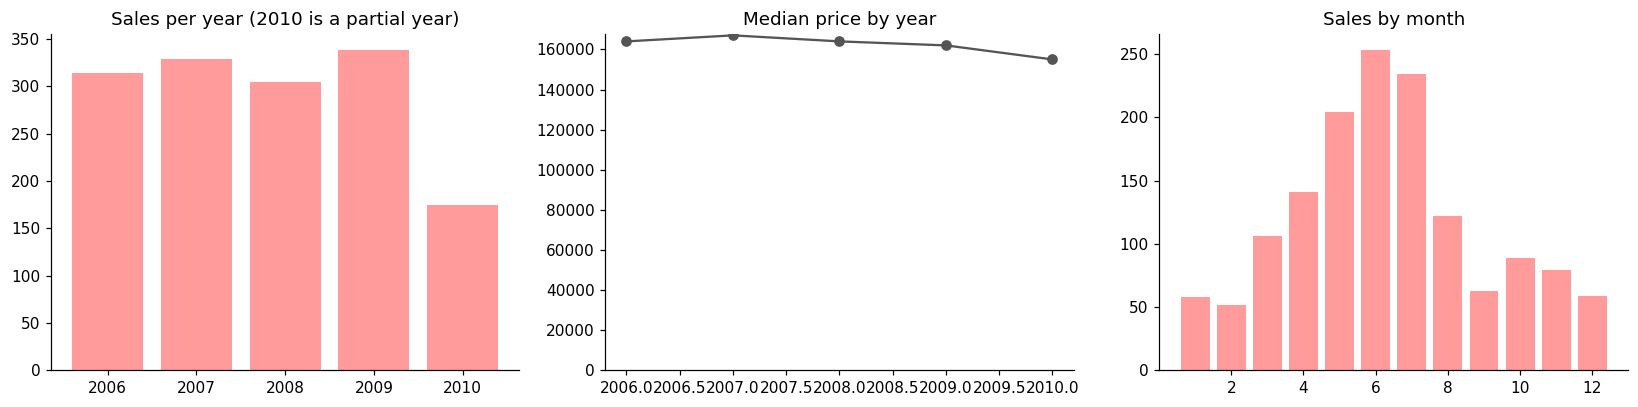

Months present in 2010: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Partial sales vs the rest (medians):


,YearBuilt,OverallQual,GrLivArea
partial,,,
False,1970.0,6.0,1440.0
True,2006.0,7.0,1646.0


SaleCondition,Abnorml,AdjLand,Alloca,Family,Normal,Partial
count,101.0,4.0,12.0,20.0,1198.0,125.0
median,130000.0,104000.0,148145.0,140500.0,160000.0,244600.0


SaleType,COD,CWD,Con,ConLD,ConLI,ConLw,New,Oth,WD
count,43.0,4.0,2.0,9.0,5.0,5.0,122.0,3.0,1267.0
median,139000.0,188750.0,269600.0,140000.0,125000.0,144000.0,247453.0,116050.0,158000.0


In [17]:
t = raw.groupby('YrSold').SalePrice.agg(['count', 'median', 'mean']).round(0); display(t)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].bar(t.index, t['count'], color=GC['Sale context']); ax[0].set_title('Sales per year (2010 is a partial year)')
ax[1].plot(t.index, t['median'], 'o-', color='#555'); ax[1].set_title('Median price by year'); ax[1].set_ylim(0, None)
mo = raw.groupby('MoSold').size(); ax[2].bar(mo.index, mo.values, color=GC['Sale context']); ax[2].set_title('Sales by month')
savefig('09_time_and_season')
print('Months present in 2010:', sorted(raw[raw.YrSold == 2010].MoSold.unique()))
print('Partial sales vs the rest (medians):'); display(raw.assign(partial=raw.SaleCondition == 'Partial').groupby('partial')[['YearBuilt', 'OverallQual', 'GrLivArea']].median())
sc = raw.groupby('SaleCondition').SalePrice.agg(['count', 'median']); st = raw.groupby('SaleType').SalePrice.agg(['count', 'median'])
display(sc.T); display(st.T)

In [18]:
g = raw.GrLivArea
print('GrLivArea > 4000:'); display(raw.loc[g > 4000, ['Id','GrLivArea','SalePrice','OverallQual','SaleCondition','Neighborhood']])
print('Largest lots:'); display(raw.nlargest(5, 'LotArea')[['Id','LotArea','SalePrice']])
# Price per sq ft: robust way to spot sales that do not fit their size
raw['ppsf'] = raw.SalePrice / raw.GrLivArea
print('Lowest price per sq ft:'); display(raw.nsmallest(6, 'ppsf')[['Id','GrLivArea','SalePrice','ppsf','SaleCondition','OverallQual']].round(1))
# internal consistency
print('GrLivArea != 1st+2nd+LowQual:', (raw.GrLivArea != raw['1stFlrSF'] + raw['2ndFlrSF'] + raw.LowQualFinSF).sum())
print('TotalBsmtSF != sum of parts :', (raw.TotalBsmtSF != raw.BsmtFinSF1 + raw.BsmtFinSF2 + raw.BsmtUnfSF).sum())
print('YearBuilt > YrSold          :', (raw.YearBuilt > raw.YrSold).sum(), '| YearRemodAdd > YrSold:', (raw.YearRemodAdd > raw.YrSold).sum(), '| Remod < Built:', (raw.YearRemodAdd < raw.YearBuilt).sum())
gy = raw.GarageYrBlt; print('GarageYrBlt > YrSold        :', (gy > raw.YrSold).sum(), '| GarageYrBlt < YearBuilt:', (gy < raw.YearBuilt).sum(), '| max GarageYrBlt:', gy.max())
raw.drop(columns='ppsf', inplace=True)

GrLivArea > 4000:


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition,Neighborhood
523,524,4676,184750,10,Partial,Edwards
691,692,4316,755000,10,Normal,NoRidge
1182,1183,4476,745000,10,Abnorml,NoRidge
1298,1299,5642,160000,10,Partial,Edwards


Largest lots:


,Id,LotArea,SalePrice
313,314,215245,375000
335,336,164660,228950
249,250,159000,277000
706,707,115149,302000
451,452,70761,280000


Lowest price per sq ft:


,Id,GrLivArea,SalePrice,ppsf,SaleCondition,OverallQual
1298,1299,5642,160000,28.4,Partial,10
30,31,1317,40000,30.4,Normal,4
1062,1063,2337,90000,38.5,Normal,5
968,969,968,37900,39.2,Abnorml,3
523,524,4676,184750,39.5,Partial,10
1292,1293,2372,107500,45.3,Normal,5


GrLivArea != 1st+2nd+LowQual: 0
TotalBsmtSF != sum of parts : 0
YearBuilt > YrSold          : 0 | YearRemodAdd > YrSold: 1 | Remod < Built: 0
GarageYrBlt > YrSold        : 0 | GarageYrBlt < YearBuilt: 9 | max GarageYrBlt: 2010.0


,a,b,r
540,GarageCars,GarageArea,0.88
148,YearBuilt,GarageYrBlt,0.83
391,GrLivArea,TotRmsAbvGrd,0.83
295,TotalBsmtSF,1stFlrSF,0.82


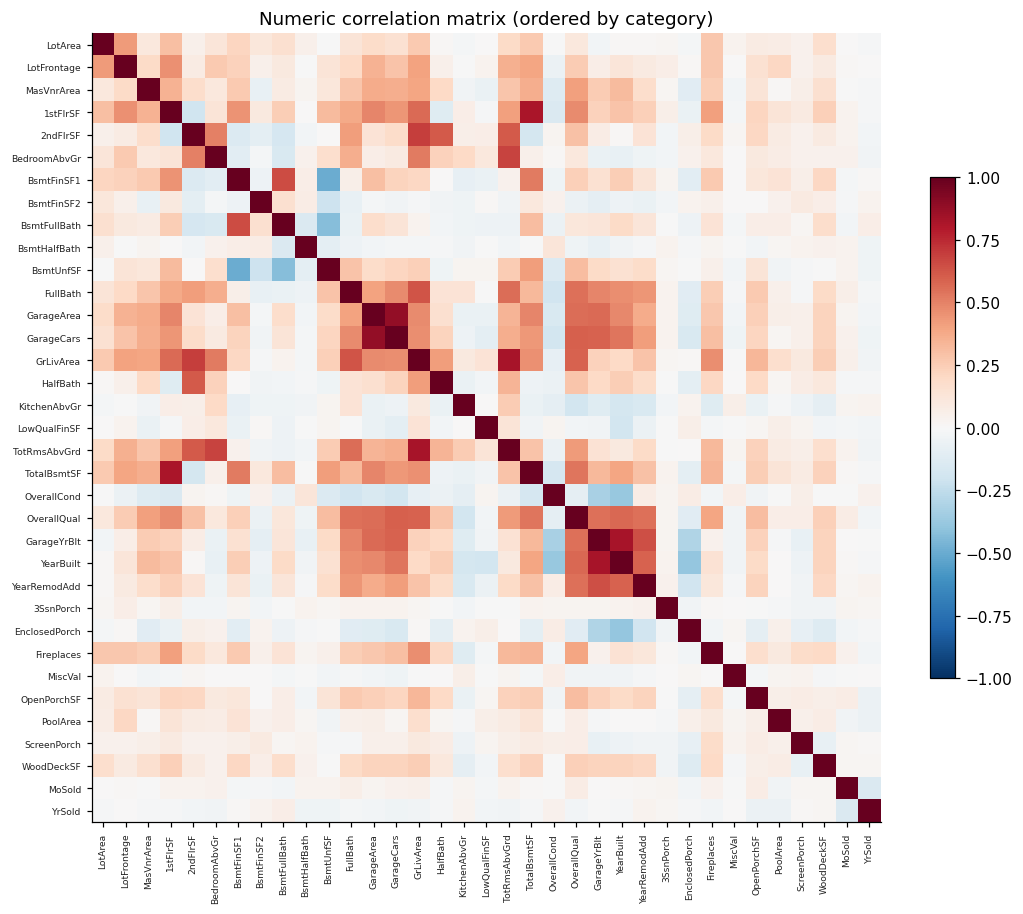

In [19]:
cm = numdf.corr()
pairs = (cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().rename('r').reset_index())
pairs.columns = ['a', 'b', 'r']
display(pairs.loc[pairs.r.abs() > 0.7].sort_values('r', key=abs, ascending=False).round(2))
fig, ax = plt.subplots(figsize=(10, 8.5))
cols = sorted(numdf.columns, key=lambda c: (list(FEATURE_GROUPS).index(COLUMN_TO_GROUP[c]), c))
im = ax.imshow(numdf[cols].corr(), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=6); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=6)
for tl in ax.get_xticklabels() + ax.get_yticklabels(): tl.set_color('#222')
plt.colorbar(im, shrink=.6); ax.set_title('Numeric correlation matrix (ordered by category)')
savefig('10_correlation_matrix')

In [20]:
audit = E.leakage_audit(raw)
audit['group'] = audit.column.map(COLUMN_TO_GROUP)
audit.to_csv(TAB / 'leakage_audit.csv', index=False)
display(audit[(audit.known_at_listing == 'No') | (audit.note != '')])
print('Rows of the audit with known_at_listing = No:', (audit.known_at_listing == 'No').sum(), '| derived_from_price = Yes:', (audit.derived_from_price == 'Yes').sum())

,column,known_at_listing,derived_from_price,note,group
11,Neighborhood,Yes,No,high-cardinality; target encoding must be fitt...,Location and lot
19,YearRemodAdd,Yes,No,1 row has remodel year after YrSold,Age
58,GarageYrBlt,Yes,No,9 rows dated before YearBuilt; redundant with ...,Age
74,MiscVal,Yes,No,dollar value of a misc feature; confirm it is ...,Amenities
75,MoSold,No,No,sale-time; not known when a listing price is set,Sale context
76,YrSold,No,No,sale-time; keep as temporal split key and age ...,Sale context
77,SaleType,No,No,describes the transaction; 'New' is also a pro...,Sale context
78,SaleCondition,No,No,transaction fact; 'Partial' = home not complet...,Sale context


Rows of the audit with known_at_listing = No: 4 | derived_from_price = Yes: 0


In [21]:
# Cost of excluding sale-context predictors, measured, not assumed. Same folds, gradient boosting, CV RMSE on log1p(price).
setups = {
    'all 79 predictors':                    dict(),
    'drop all four sale-context columns':   dict(drop_cols=E.SALE_CONTEXT),
    'drop SaleType + SaleCondition only':   dict(drop_cols=['SaleType', 'SaleCondition']),
    'drop MoSold + YrSold only':            dict(drop_cols=['MoSold', 'YrSold']),
}
rows = [(k,) + E.cv_rmse(raw, **v) for k, v in setups.items()]
abl = pd.DataFrame(rows, columns=['setup', 'cv_rmse_log', 'sd_over_folds']).round(4)
abl['delta_vs_all'] = (abl.cv_rmse_log - abl.cv_rmse_log.iloc[0]).round(4)
abl.to_csv(TAB / 'ablation_sale_context.csv', index=False); abl

,setup,cv_rmse_log,sd_over_folds,delta_vs_all
0,all 79 predictors,0.1311,0.0134,0.0000
1,drop all four sale-context columns,0.1319,0.0139,0.0008
2,drop SaleType + SaleCondition only,0.1324,0.0140,0.0013
3,drop MoSold + YrSold only,0.1312,0.0136,0.0001


In [22]:
# Effect of the two outliers, measured fairly: same validation rows (outliers excluded) with and without them in training.
fair = pd.DataFrame([
    ('evaluate incl. outliers, train incl.',        *E.cv_rmse(raw)),
    ('evaluate excl. outliers, train incl.',        *E.cv_rmse(raw, eval_exclude_ids=E.OUTLIER_IDS)),
    ('evaluate excl. outliers, train excl. (drop)', *E.cv_rmse(raw, drop_train_ids=E.OUTLIER_IDS, eval_exclude_ids=E.OUTLIER_IDS)),
], columns=['setup', 'cv_rmse_log', 'sd_over_folds']).round(4)
fair.to_csv(TAB / 'ablation_outliers.csv', index=False); fair

,setup,cv_rmse_log,sd_over_folds
0,"evaluate incl. outliers, train incl.",0.1311,0.0134
1,"evaluate excl. outliers, train incl.",0.1255,0.0122
2,"evaluate excl. outliers, train excl. (drop)",0.1238,0.0120


probe R2 = 0.752, residual SD (log) = 0.199 (~22% typical error)
Residual by PREDICTED price band:


,count,mean,std
band_pred,,,
Q1 low,293,0.032,0.208
Q2,292,-0.005,0.204
Q3,292,-0.034,0.173
Q4,291,-0.031,0.186
Q5 high,292,0.038,0.211


Residual by ACTUAL price band (biased view, see insight):


,count,mean,std
band_actual,,,
Q1 low,295,-0.157,0.228
Q2,294,0.003,0.179
Q3,287,0.010,0.177
Q4,295,0.025,0.142
Q5 high,289,0.122,0.150


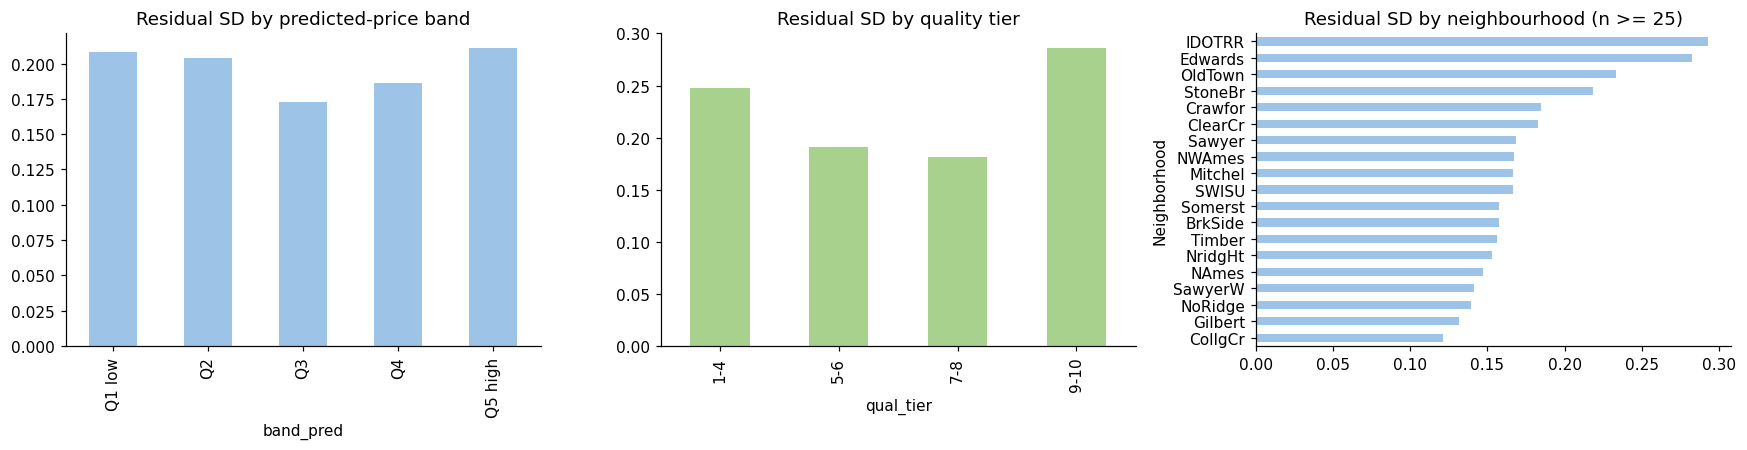

In [23]:
Xp = np.c_[np.ones(len(raw)), np.log(raw.GrLivArea), raw.OverallQual]
beta = np.linalg.lstsq(Xp, logp, rcond=None)[0]
pred = Xp @ beta; res = logp - pred
pr = raw.assign(res=res, pred=pred)
print(f'probe R2 = {1 - res.var() / logp.var():.3f}, residual SD (log) = {res.std():.3f} (~{100 * (np.exp(res.std()) - 1):.0f}% typical error)')
pr['band_pred'] = pd.qcut(pr.pred, 5, labels=['Q1 low', 'Q2', 'Q3', 'Q4', 'Q5 high'])
pr['band_actual'] = pd.qcut(pr.SalePrice, 5, labels=['Q1 low', 'Q2', 'Q3', 'Q4', 'Q5 high'])
pr['qual_tier'] = pd.cut(pr.OverallQual, [0, 4, 6, 8, 10], labels=['1-4', '5-6', '7-8', '9-10'])
by_pred = pr.groupby('band_pred', observed=True).res.agg(['count', 'mean', 'std']).round(3)
by_act = pr.groupby('band_actual', observed=True).res.agg(['count', 'mean', 'std']).round(3)
by_q = pr.groupby('qual_tier', observed=True).res.agg(['count', 'std']).round(3)
nbs = pr.groupby('Neighborhood').res.agg(['count', 'std']); nbs = nbs[nbs['count'] >= 25].sort_values('std')
print('Residual by PREDICTED price band:'); display(by_pred)
print('Residual by ACTUAL price band (biased view, see insight):'); display(by_act)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
by_pred['std'].plot.bar(ax=ax[0], color='#9DC3E6'); ax[0].set_title('Residual SD by predicted-price band')
by_q['std'].plot.bar(ax=ax[1], color=GC['Quality and condition']); ax[1].set_title('Residual SD by quality tier')
nbs['std'].plot.barh(ax=ax[2], color=GC['Location and lot']); ax[2].set_title('Residual SD by neighbourhood (n >= 25)')
savefig('11_uncertainty_by_segment')

In [24]:
assoc, auc = E.missingness_association(raw, 'LotFrontage')
assoc.to_csv(TAB / 'lotfrontage_missingness_assoc.csv', index=False)
print(f'Cross-validated AUC for predicting "LotFrontage is missing" from all other predictors: {auc:.3f}  (0.5 = missing completely at random)')
print('Variables significantly associated with missingness (Bonferroni, alpha = 0.01):', int(assoc.significant.sum()), 'of', len(assoc))
display(assoc.head(10).round(4))

Cross-validated AUC for predicting "LotFrontage is missing" from all other predictors: 0.841  (0.5 = missing completely at random)
Variables significantly associated with missingness (Bonferroni, alpha = 0.01): 17 of 78


,variable,kind,p_value,effect_size,p_bonferroni,significant
37,LotShape,categorical,0.0000,0.3355,0.0000,True
42,Neighborhood,categorical,0.0000,0.3097,0.0000,True
40,LotConfig,categorical,0.0000,0.2693,0.0000,True
50,Exterior2nd,categorical,0.0000,0.2052,0.0000,True
0,LotArea,numeric,0.0000,0.1992,0.0000,True
49,Exterior1st,categorical,0.0000,0.1944,0.0001,True
66,FireplaceQu,categorical,0.0000,0.1885,0.0000,True
21,Fireplaces,numeric,0.0000,0.1807,0.0000,True
77,MSSubClass,categorical,0.0001,0.1731,0.0051,True
8,BsmtUnfSF,numeric,0.0000,0.1665,0.0020,True


In [25]:
# Which fill recovers hidden known LotFrontage values best? (statistics computed on training folds only)
imp = E.compare_lotfrontage_imputers(raw).round(2)
imp.to_csv(TAB / 'lotfrontage_imputer_comparison.csv', index=False); display(imp)
k = (raw.LotFrontage / np.sqrt(raw.LotArea)); print('LotFrontage / sqrt(LotArea): median', round(k.median(), 2), '| IQR', round(k.quantile(.25), 2), '-', round(k.quantile(.75), 2))

,imputer,RMSE (ft),MAE (ft)
3,ratio to sqrt(LotArea) by Neighborhood,19.67,11.12
1,median by Neighborhood,22.25,13.26
2,median by Neighborhood+LotConfig,22.28,12.80
0,global median,24.30,16.76


LotFrontage / sqrt(LotArea): median 0.72 | IQR 0.63 - 0.81


,feature,group,kind,pearson,spearman,eta_squared,mutual_info,mi_rank,assoc_rank
0,OverallQual,Quality and condition,numeric,0.817,0.810,NaN,0.570,1,1
1,Neighborhood,Location and lot,categorical,NaN,NaN,0.571,0.524,2,2
2,GrLivArea,Size,numeric,0.701,0.731,NaN,0.457,3,3
3,GarageCars,Size,numeric,0.681,0.691,NaN,0.363,4,4
4,GarageArea,Size,numeric,0.651,0.649,NaN,0.363,5,9
5,TotalBsmtSF,Size,numeric,0.612,0.603,NaN,0.360,6,12
6,YearBuilt,Age,numeric,0.587,0.653,NaN,0.360,7,8
7,BsmtQual,Quality and condition,categorical,NaN,NaN,0.452,0.327,8,6
8,ExterQual,Quality and condition,categorical,NaN,NaN,0.461,0.321,9,5
9,KitchenQual,Quality and condition,categorical,NaN,NaN,0.448,0.319,10,7


Weakest 15 by mutual information:


,feature,group,kind,pearson,spearman,eta_squared,mutual_info,mi_rank,assoc_rank
64,Functional,Dwelling type and structure,categorical,NaN,NaN,0.024,0.011,65,61
65,LowQualFinSF,Size,numeric,-0.038,-0.068,NaN,0.006,66,70
66,RoofMatl,Dwelling type and structure,categorical,NaN,NaN,0.018,0.006,67,63
67,BsmtFinSF2,Size,numeric,0.005,-0.039,NaN,0.005,68,75
68,LandSlope,Location and lot,categorical,NaN,NaN,0.001,0.004,69,76
69,MiscVal,Amenities,numeric,-0.020,-0.063,NaN,0.002,70,72
70,Condition2,Location and lot,categorical,NaN,NaN,0.012,0.002,71,65
71,MiscFeature,Amenities,categorical,NaN,NaN,0.010,0.002,72,67
72,Street,Location and lot,categorical,NaN,NaN,0.003,0.001,73,74
73,YrSold,Sale context,numeric,-0.037,-0.030,NaN,0.001,74,77


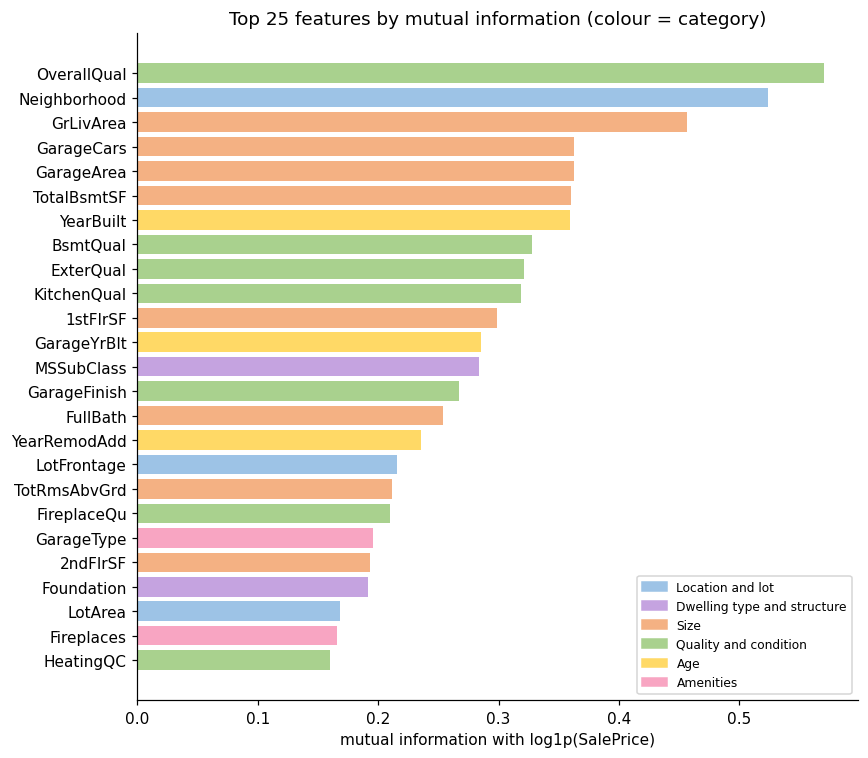

In [26]:
sig = E.signal_table(raw)
sig['group'] = sig.feature.map(COLUMN_TO_GROUP)
sig.to_csv(TAB / 'signal_table.csv', index=False)
disp = sig[['feature', 'group', 'kind', 'pearson', 'spearman', 'eta_squared', 'mutual_info', 'mi_rank', 'assoc_rank']].round(3)
display(disp.head(25))
print('Weakest 15 by mutual information:'); display(disp.tail(15))
top = sig.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.feature, top.mutual_info, color=[GC[g] for g in top.group])
ax.set_xlabel('mutual information with log1p(SalePrice)'); ax.set_title('Top 25 features by mutual information (colour = category)')
ax.legend(handles=[Patch(color=GC[g], label=g) for g in GC if g in set(top.group)], fontsize=8, loc='lower right')
savefig('12_signal_table')

In [27]:
# Where do Pearson and mutual information disagree most? These are the non-linear / categorical signals a correlation-only screen would miss.
sig['mi_pct'] = sig.mutual_info.rank(pct=True); sig['lin_pct'] = sig.pearson.abs().rank(pct=True)
d_ = sig.dropna(subset=['pearson']).assign(gap=lambda t: t.mi_pct - t.lin_pct).sort_values('gap', ascending=False)
display(d_[['feature', 'pearson', 'spearman', 'mutual_info', 'gap']].head(8).round(3))

,feature,pearson,spearman,mutual_info,gap
32,OverallCond,-0.037,-0.129,0.113,0.481
22,LotArea,0.257,0.456,0.168,0.264
20,2ndFlrSF,0.319,0.294,0.193,0.233
30,BsmtUnfSF,0.222,0.185,0.125,0.220
16,LotFrontage,0.356,0.409,0.215,0.197
62,BsmtHalfBath,-0.005,-0.012,0.014,0.158
26,OpenPorchSF,0.321,0.478,0.156,0.128
6,YearBuilt,0.587,0.653,0.360,0.124


In [28]:
clus, vif, spear = E.correlation_clusters(raw, threshold=0.7)
clus.to_csv(TAB / 'correlation_clusters.csv', index=False)
print('Clusters of numeric features with |Spearman| >= 0.7 (suggest_keep = strongest signal in each cluster):'); display(clus.round(2))
v = vif.round(1).to_frame('VIF'); v['note'] = np.where(np.isinf(vif), 'exact linear combination of other columns', '')
display(v.head(14))

Clusters of numeric features with |Spearman| >= 0.7 (suggest_keep = strongest signal in each cluster):


,feature,cluster,abs_spearman_price,suggest_keep
0,GrLivArea,13,0.73,True
1,TotRmsAbvGrd,13,0.53,False
2,GarageCars,16,0.69,True
3,GarageArea,16,0.65,False
4,YearBuilt,17,0.65,True
5,GarageYrBlt,17,0.56,False
6,TotalBsmtSF,22,0.60,True
7,1stFlrSF,22,0.58,False


,VIF,note
TotalBsmtSF,inf,exact linear combination of other columns
GrLivArea,inf,exact linear combination of other columns
BsmtFinSF1,inf,exact linear combination of other columns
BsmtFinSF2,inf,exact linear combination of other columns
BsmtUnfSF,inf,exact linear combination of other columns
1stFlrSF,inf,exact linear combination of other columns
2ndFlrSF,inf,exact linear combination of other columns
LowQualFinSF,inf,exact linear combination of other columns
GarageCars,5.6,
GarageArea,5.4,


        oof_RMSE_log  Levene p (pred_band)  Levene p (qual_tier)  Levene p (Neighborhood)
linear        0.1996                0.3775                0.0033                      0.0
gbm           0.1365                0.0000                0.0000                      0.0

linear: residual SD (log) by segment


qual_tier,1-4,5-6,7-8,9-10
count,141.000,771.000,487.000,61.00
std,0.249,0.192,0.181,0.29


  neighbourhood SD: min CollgCr 0.122 -> max IDOTRR 0.294 (ratio 2.4x)

gbm: residual SD (log) by segment


qual_tier,1-4,5-6,7-8,9-10
count,141.000,771.000,487.000,61.000
std,0.197,0.117,0.123,0.251


  neighbourhood SD: min CollgCr 0.071 -> max IDOTRR 0.250 (ratio 3.5x)


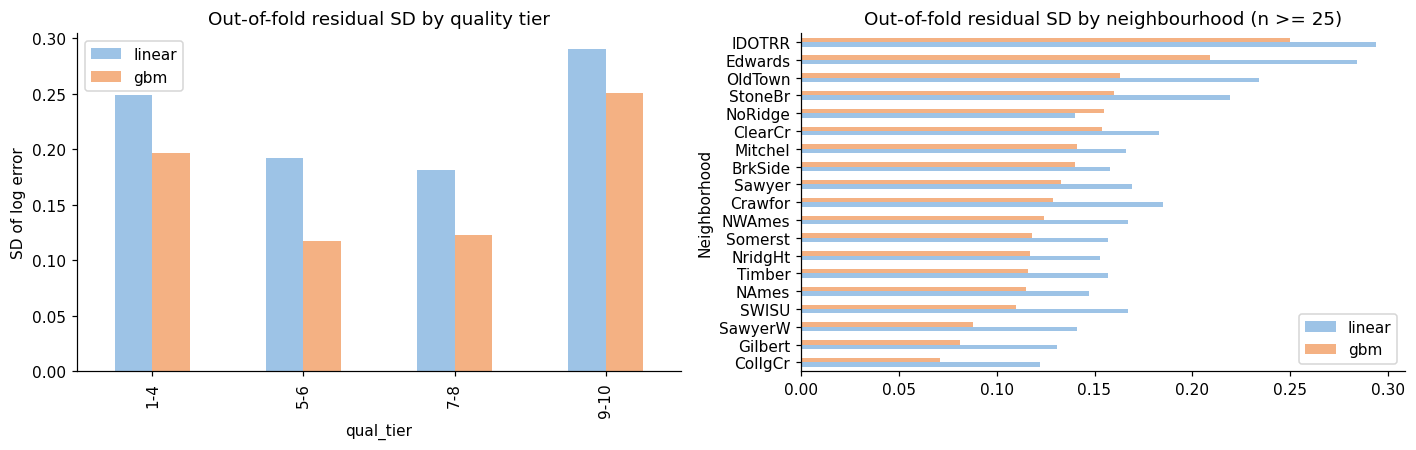

In [29]:
rows = {}
res_store = {}
for name in ['linear', 'gbm']:
    pred, res = E.oof_residuals(raw, name)
    out, tests, dd = E.segment_spread(raw, pred, res)
    rows[name] = (np.sqrt(np.mean(res ** 2)), tests)
    res_store[name] = out
print(pd.DataFrame({k: {'oof_RMSE_log': round(v[0], 4), **{f'Levene p ({s})': round(p, 4) for s, p in v[1].items()}} for k, v in rows.items()}).T.to_string())
for name in ['linear', 'gbm']:
    print(f'\n{name}: residual SD (log) by segment'); display(res_store[name]['qual_tier'][['count', 'std']].T)
    nbs = res_store[name]['Neighborhood']['std'].sort_values()
    print(f'  neighbourhood SD: min {nbs.index[0]} {nbs.iloc[0]:.3f} -> max {nbs.index[-1]} {nbs.iloc[-1]:.3f} (ratio {nbs.iloc[-1] / nbs.iloc[0]:.1f}x)')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
q = pd.DataFrame({k: res_store[k]['qual_tier']['std'] for k in res_store})
q.plot.bar(ax=ax[0], color=['#9DC3E6', '#F4B183']); ax[0].set_title('Out-of-fold residual SD by quality tier'); ax[0].set_ylabel('SD of log error')
n = pd.DataFrame({k: res_store[k]['Neighborhood']['std'] for k in res_store}).sort_values('gbm')
n.plot.barh(ax=ax[1], color=['#9DC3E6', '#F4B183']); ax[1].set_title('Out-of-fold residual SD by neighbourhood (n >= 25)')
savefig('13_cv_uncertainty_probe')